# Financial Modeling Toolkit for Banking Analytics
**From time value of money to credit risk, portfolio theory, VaR and DCF valuation, in Python**

*Master's project: Business Analytics / Financial Management*

**What this notebook is.** One end-to-end project that builds the core models used in banking and corporate finance, with the concept explained before each model. Every model is a reusable function, validated with a sanity check, and ends with a "so what" for a decision-maker.

| # | Module | Core concept | Where it's used in a bank |
|---|--------|--------------|---------------------------|
| 1 | Time value of money | PV, FV, annuities | Pricing every product |
| 2 | Loan amortization | Payment schedules, prepayment | Mortgage / personal loan desks |
| 3 | Capital budgeting | NPV, IRR, payback | Project and branch investment decisions |
| 4 | Bond analytics | YTM, duration, convexity | Treasury / ALM, interest-rate risk |
| 5 | Risk & return, CAPM | Beta, Sharpe, cost of equity | Performance measurement |
| 6 | Portfolio optimization | Efficient frontier | Investment / wealth management |
| 7 | Value at Risk | Historical, parametric, Monte Carlo VaR, ES | Market-risk limits, Basel |
| 8 | Credit risk | PD x LGD x EAD, expected credit loss, risk-based pricing | Lending, IFRS 9 / CECL provisioning |
| 9 | WACC & DCF | Free cash flow, terminal value, sensitivity | Valuation, M&A, credit analysis |
| 10 | Monte Carlo valuation | Uncertainty in valuation | Scenario / stress analysis |

**Data note.** All data is simulated with a fixed random seed so results are reproducible and no client data is used. Section 11 shows how to swap in real market data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

np.random.seed(42)
pd.options.display.float_format = '{:,.4f}'.format
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

## 1. Time Value of Money
**Concept.** A dollar today is worth more than a dollar tomorrow because it can earn interest. Everything in finance is built on two operations:

- Future value: $FV = PV (1+r)^n$
- Present value: $PV = \dfrac{FV}{(1+r)^n}$
- Annuity (level payments $C$ for $n$ periods): $PV = C\,\dfrac{1-(1+r)^{-n}}{r}$

The effective annual rate (EAR) of a nominal rate $r$ compounded $m$ times a year is $(1+r/m)^m - 1$. Banks quote APR but customers earn/pay EAR, so the two must not be confused.

In [2]:
def fv(pv, r, n):            return pv * (1 + r) ** n
def pv_(fv_, r, n):          return fv_ / (1 + r) ** n
def pv_annuity(c, r, n):     return c * (1 - (1 + r) ** -n) / r
def ear(nominal, m):         return (1 + nominal / m) ** m - 1

print(f"$10,000 at 5% for 10y -> ${fv(10_000, .05, 10):,.2f}")
print(f"PV of $50,000 in 8y @6% -> ${pv_(50_000, .06, 8):,.2f}")
print(f"PV of $1,000/yr for 20y @7% -> ${pv_annuity(1_000, .07, 20):,.2f}")

# Compounding frequency: same 6% APR, different effective cost
freq = {'Annual': 1, 'Quarterly': 4, 'Monthly': 12, 'Daily': 365}
print(pd.Series({k: ear(.06, m) for k, m in freq.items()}, name='EAR on 6% APR'))

$10,000 at 5% for 10y -> $16,288.95
PV of $50,000 in 8y @6% -> $31,370.62
PV of $1,000/yr for 20y @7% -> $10,594.01
Annual      0.0600
Quarterly   0.0614
Monthly     0.0617
Daily       0.0618
Name: EAR on 6% APR, dtype: float64


## 2. Loan Amortization (mortgage engine)
**Concept.** A fully amortizing loan has a constant payment $P = L\,\dfrac{r}{1-(1+r)^{-n}}$ (monthly $r$, $n$ months). Early payments are mostly interest; later ones mostly principal. Extra principal payments shorten the loan and cut total interest, which is why prepayment matters to a bank's income forecasts.

Monthly payment: $2,528.27
Total interest (base):   $510,178  over 360 months
Total interest (+$300):  $360,597  over 269 months
Interest saved: $149,581; 7.6 years earlier


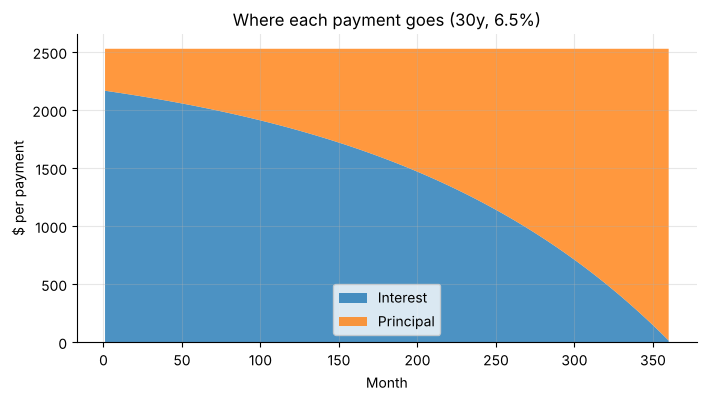

In [3]:
def amortization(principal, annual_rate, years, extra=0.0):
    r, n = annual_rate / 12, years * 12
    pmt = principal * r / (1 - (1 + r) ** -n)
    bal, rows = principal, []
    for m in range(1, n + 1):
        interest = bal * r
        princ = min(pmt - interest + extra, bal)
        bal -= princ
        rows.append((m, pmt, interest, princ, bal))
        if bal <= 1e-8: break
    return pd.DataFrame(rows, columns=['month', 'payment', 'interest', 'principal', 'balance']).set_index('month')

base  = amortization(400_000, .065, 30)
extra = amortization(400_000, .065, 30, extra=300)
print(f"Monthly payment: ${base.payment.iloc[0]:,.2f}")
print(f"Total interest (base):   ${base.interest.sum():,.0f}  over {len(base)} months")
print(f"Total interest (+$300):  ${extra.interest.sum():,.0f}  over {len(extra)} months")
print(f"Interest saved: ${base.interest.sum()-extra.interest.sum():,.0f}; "
      f"{(len(base)-len(extra))/12:.1f} years earlier")

fig, ax = plt.subplots()
ax.stackplot(base.index, base.interest, base.principal, labels=['Interest', 'Principal'], alpha=.8)
ax.set(title='Where each payment goes (30y, 6.5%)', xlabel='Month', ylabel='$ per payment'); ax.legend()
plt.show()

**Takeaway.** On a 30-year 6.5% loan the borrower pays back close to double the amount borrowed in interest; a modest $300/month extra payment saves a six-figure sum. For the bank, faster prepayment shortens asset duration and reduces expected interest income.

## 3. Capital Budgeting: NPV, IRR, Payback
**Concept.** Accept a project if its Net Present Value is positive:

$$NPV = \sum_{t=0}^{T}\frac{CF_t}{(1+r)^t}$$

IRR is the discount rate that sets NPV = 0. Use NPV for decisions (it measures value created in dollars). IRR can mislead with non-conventional cash flows or when ranking mutually exclusive projects of different scale.

                    NPV @9%    IRR  Payback (yrs)
Digital platform 1,009.4702 0.2429         3.0000
Branch expansion   398.9541 0.1861         3.1000


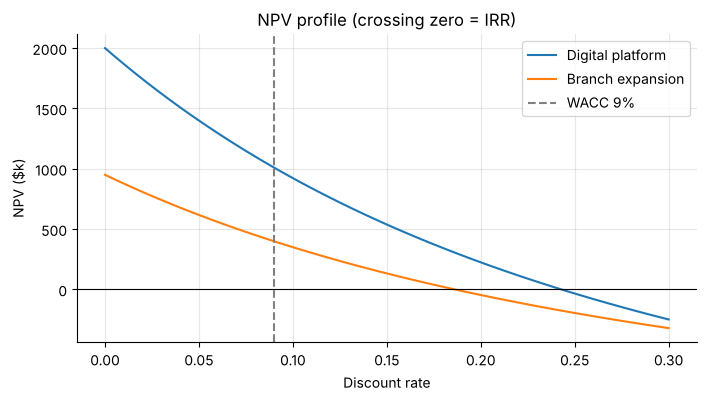

In [4]:
def npv(rate, cfs):  return sum(cf / (1 + rate) ** t for t, cf in enumerate(cfs))
def irr(cfs):        return optimize.brentq(lambda r: npv(r, cfs), -0.99, 10)
def payback(cfs):
    cum = np.cumsum(cfs)
    idx = np.argmax(cum >= 0) if (cum >= 0).any() else None
    if idx is None: return np.nan
    return idx - 1 + (-cum[idx-1] / cfs[idx])

# Example: new digital-banking platform vs. branch expansion (in $ thousands)
projects = {'Digital platform':   [-2000, 400, 700, 900, 1000, 1000],
            'Branch expansion':   [-1500, 450, 500, 500, 500, 500]}
wacc = 0.09
tbl = pd.DataFrame({k: {'NPV @9%': npv(wacc, v), 'IRR': irr(v), 'Payback (yrs)': payback(v)}
                    for k, v in projects.items()}).T
print(tbl)

rates = np.linspace(0, .3, 100)
fig, ax = plt.subplots()
for k, v in projects.items(): ax.plot(rates, [npv(r, v) for r in rates], label=k)
ax.axhline(0, c='k', lw=.8); ax.axvline(wacc, c='grey', ls='--', label='WACC 9%')
ax.set(title='NPV profile (crossing zero = IRR)', xlabel='Discount rate', ylabel='NPV ($k)'); ax.legend()
plt.show()

**Takeaway.** The NPV profiles show how sensitive each project is to the discount rate: the steeper line has more value in distant cash flows and is more exposed if rates rise.

## 4. Bond Analytics: Price, YTM, Duration, Convexity
**Concept.** A bond's price is the PV of its coupons and principal at the yield. Banks hold large bond portfolios, so rate sensitivity is central to Asset-Liability Management (ALM).

- **Macaulay duration**: PV-weighted average time to cash flows.
- **Modified duration** $D_{mod}=D_{mac}/(1+y)$: approximate % price change for a 1-unit change in yield.
- **Convexity** corrects the duration estimate for large moves:  
$\dfrac{\Delta P}{P}\approx -D_{mod}\Delta y + \tfrac12 C\,\Delta y^2$

In [5]:
def bond_cfs(face, cpn_rate, years, freq=2):
    n = int(years * freq)
    cfs = np.full(n, face * cpn_rate / freq); cfs[-1] += face
    return np.arange(1, n + 1) / freq, cfs

def bond_price(face, cpn_rate, ytm, years, freq=2):
    t, cf = bond_cfs(face, cpn_rate, years, freq)
    return np.sum(cf / (1 + ytm / freq) ** (t * freq))

def bond_ytm(price, face, cpn_rate, years, freq=2):
    return optimize.brentq(lambda y: bond_price(face, cpn_rate, y, years, freq) - price, 1e-6, 1)

def duration_convexity(face, cpn_rate, ytm, years, freq=2):
    t, cf = bond_cfs(face, cpn_rate, years, freq)
    disc = cf / (1 + ytm / freq) ** (t * freq); p = disc.sum()
    mac = np.sum(t * disc) / p
    mod = mac / (1 + ytm / freq)
    conv = np.sum(disc * t * (t + 1 / freq)) / (p * (1 + ytm / freq) ** 2)
    return mac, mod, conv

F, c, y, T = 1000, .05, .05, 10
p0 = bond_price(F, c, y, T)
mac, mod, conv = duration_convexity(F, c, y, T)
print(f"Price {p0:,.2f} | Macaulay {mac:.3f}y | Modified {mod:.3f} | Convexity {conv:.2f}")
print(f"YTM recovered from price 950: {bond_ytm(950, F, c, T):.4%}")

shocks = np.array([-.02, -.01, -.005, .005, .01, .02])
exact = np.array([bond_price(F, c, y + s, T) / p0 - 1 for s in shocks])
dur_only = -mod * shocks
dur_conv = -mod * shocks + .5 * conv * shocks ** 2
print(pd.DataFrame({'Exact': exact, 'Duration only': dur_only, 'Duration+Convexity': dur_conv},
                   index=[f"{s*1e4:+.0f}bp" for s in shocks]))

Price 1,000.00 | Macaulay 7.989y | Modified 7.795 | Convexity 73.63
YTM recovered from price 950: 5.6617%
         Exact  Duration only  Duration+Convexity
-200bp  0.1717         0.1559              0.1706
-100bp  0.0818         0.0779              0.0816
-50bp   0.0399         0.0390              0.0399
+50bp  -0.0381        -0.0390             -0.0381
+100bp -0.0744        -0.0779             -0.0743
+200bp -0.1421        -0.1559             -0.1412


**Takeaway.** Duration alone under-estimates gains when yields fall and over-estimates losses when they rise; adding convexity closes most of the gap. A 100bp shock on a 10-year par bond moves the price roughly 7-8%, the kind of number an ALM committee reviews.

## 5. Risk, Return and CAPM
**Concept.** Investors are paid only for systematic (market) risk. CAPM:

$$E[R_i] = r_f + \beta_i\,(E[R_m]-r_f), \qquad \beta_i=\frac{\mathrm{Cov}(R_i,R_m)}{\mathrm{Var}(R_m)}$$

The Sharpe ratio $=(R_p-r_f)/\sigma_p$ measures excess return per unit of total risk.

We simulate 5 years of daily returns for a market index and five assets with chosen true betas, then **estimate** the betas by regression to confirm the method recovers them.

In [6]:
days, rf = 252 * 5, 0.04
mkt_mu, mkt_sig = .08, .16
true_beta = {'Bank': 1.2, 'Tech': 1.4, 'Utility': .5, 'Retail': .9, 'Energy': 1.1}
idio_sig = {'Bank': .12, 'Tech': .20, 'Utility': .08, 'Retail': .14, 'Energy': .22}

mkt = np.random.normal(0, mkt_sig / np.sqrt(252), days)
mkt = mkt - mkt.mean() + mkt_mu / 252      # pin sample mean to the target so results are interpretable
rets = pd.DataFrame({k: rf / 252 + b * (mkt - rf / 252) + np.random.normal(0, idio_sig[k] / np.sqrt(252), days)
                     for k, b in true_beta.items()})
rets['Market'] = mkt

rows = {}
for a in true_beta:
    slope, intercept, r, p, se = stats.linregress(rets.Market, rets[a])
    rows[a] = {'True beta': true_beta[a], 'Est. beta': slope, 'R^2': r ** 2,
               'Ann. return': rets[a].mean() * 252, 'Ann. vol': rets[a].std() * np.sqrt(252)}
capm = pd.DataFrame(rows).T
mrp = rets.Market.mean() * 252 - rf
capm['CAPM req. return'] = rf + capm['Est. beta'] * mrp
capm['Sharpe'] = (capm['Ann. return'] - rf) / capm['Ann. vol']
print(capm.round(3))

         True beta  Est. beta    R^2  Ann. return  Ann. vol  CAPM req. return  \
Bank        1.2000     1.1970 0.7230       0.1410    0.2230            0.0880   
Tech        1.4000     1.4070 0.5410       0.1230    0.3030            0.0960   
Utility     0.5000     0.5040 0.5010      -0.0000    0.1130            0.0600   
Retail      0.9000     0.8870 0.5040      -0.0050    0.1980            0.0750   
Energy      1.1000     1.0730 0.3510      -0.0030    0.2870            0.0830   

         Sharpe  
Bank     0.4520  
Tech     0.2730  
Utility -0.3590  
Retail  -0.2260  
Energy  -0.1500  


**Takeaway.** The regression recovers the true betas, and `R^2` shows how much of each asset's variance is market-driven versus diversifiable. The CAPM required return becomes the **cost of equity** we use in the WACC in Section 9.

## 6. Portfolio Optimization (Markowitz)
**Concept.** Portfolio variance depends on correlations: $\sigma_p^2=w^T\Sigma w$. Combining imperfectly correlated assets lowers risk without lowering expected return. The **efficient frontier** is the set of portfolios with the highest return for each risk level; the **tangency portfolio** maximizes the Sharpe ratio.

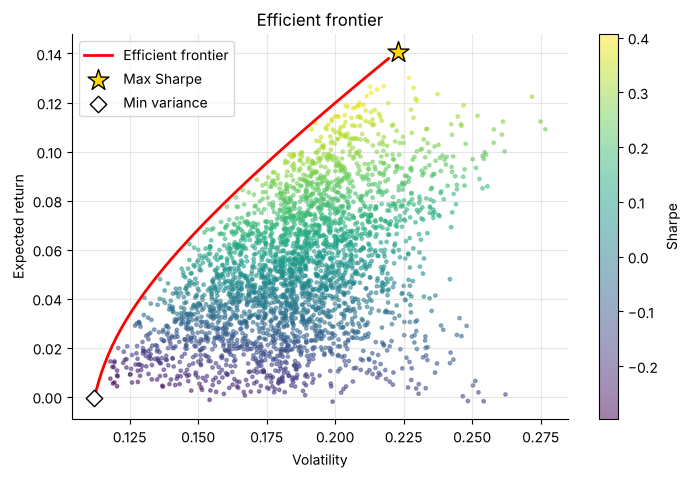

         Max Sharpe  Min variance  Equal weight
Bank         1.0000        0.0000        0.2000
Tech         0.0000        0.0000        0.2000
Utility      0.0000        0.9350        0.2000
Retail       0.0000        0.0650        0.2000
Energy       0.0000        0.0000        0.2000
Max Sharpe    return 14.08%  vol 22.30%  Sharpe 0.45
Min variance  return -0.07%  vol 11.21%  Sharpe -0.36
Equal weight  return 5.10%  vol 17.65%  Sharpe 0.06


In [7]:
assets = list(true_beta)
mu = rets[assets].mean().values * 252
cov = rets[assets].cov().values * 252

def port_stats(w): return w @ mu, np.sqrt(w @ cov @ w)
cons = ({'type': 'eq', 'fun': lambda w: w.sum() - 1},)
bnds = [(0, 1)] * len(assets)
w0 = np.ones(len(assets)) / len(assets)

# Max-Sharpe (tangency) and min-variance portfolios, long-only
tang = optimize.minimize(lambda w: -(port_stats(w)[0] - rf) / port_stats(w)[1], w0, bounds=bnds, constraints=cons).x
minv = optimize.minimize(lambda w: port_stats(w)[1], w0, bounds=bnds, constraints=cons).x

# Efficient frontier: minimise vol for each target return
targets = np.linspace(port_stats(minv)[0], mu.max() * .98, 40)
front = []
for t in targets:
    c2 = cons + ({'type': 'eq', 'fun': lambda w, t=t: port_stats(w)[0] - t},)
    res = optimize.minimize(lambda w: port_stats(w)[1], w0, bounds=bnds, constraints=c2)
    front.append((res.fun, t))
front = np.array(front)

# Random portfolios for context
rw = np.random.dirichlet(np.ones(len(assets)), 3000)
rp = np.array([port_stats(w) for w in rw])

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rp[:, 1], rp[:, 0], c=(rp[:, 0] - rf) / rp[:, 1], s=6, cmap='viridis', alpha=.5)
ax.plot(front[:, 0], front[:, 1], 'r-', lw=2, label='Efficient frontier')
ax.scatter(port_stats(tang)[1], port_stats(tang)[0], marker='*', s=250, c='gold', ec='k', label='Max Sharpe', zorder=5)
ax.scatter(port_stats(minv)[1], port_stats(minv)[0], marker='D', s=70, c='white', ec='k', label='Min variance', zorder=5)
ax.set(title='Efficient frontier', xlabel='Volatility', ylabel='Expected return'); ax.legend(); plt.colorbar(sc, label='Sharpe')
plt.show()

print(pd.DataFrame({'Max Sharpe': tang, 'Min variance': minv, 'Equal weight': w0}, index=assets).round(3))
for n, w in [('Max Sharpe', tang), ('Min variance', minv), ('Equal weight', w0)]:
    r_, s_ = port_stats(w); print(f"{n:13s} return {r_:.2%}  vol {s_:.2%}  Sharpe {(r_-rf)/s_:.2f}")

**Takeaway.** The optimizer concentrates in assets with the best risk-adjusted return. In practice, estimated means are noisy, so optimized weights are sensitive to inputs; real desks add constraints, shrinkage or Black-Litterman views.

## 7. Value at Risk (VaR) and Expected Shortfall
**Concept.** VaR at 99% / 1-day answers: *"What loss will not be exceeded on 99% of days?"* Expected Shortfall (ES) is the average loss in the worst 1% tail and is what Basel's FRTB now uses because VaR ignores tail severity.

Three methods:
1. **Historical**: percentile of past returns (no distribution assumption).
2. **Parametric (variance-covariance)**: assumes normality, $VaR=\mu - z_\alpha\sigma$.
3. **Monte Carlo**: simulate from a fitted model.

We use fat-tailed (Student-t) returns so you can see where the normal assumption breaks down.

                       VaR 99%    ES 99%
Historical            $342,604  $405,748
Parametric            $349,848  $401,746
Monte Carlo (normal)  $348,768  $400,727
Historical: exceptions 1.03% (target 1.00%)
Parametric: exceptions 0.95% (target 1.00%)


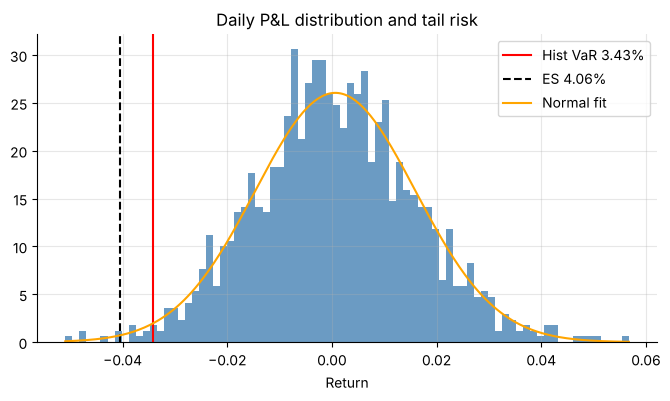

In [8]:
# Portfolio of $10M in the max-Sharpe weights, with fat-tailed shocks added to mimic real markets
V = 10_000_000
base_ret = rets[assets].values @ tang
fat = base_ret + stats.t.rvs(df=3, size=len(base_ret)) * base_ret.std() * .25   # heavy tails
pr = pd.Series(fat)

def var_es(r, alpha=.99):
    q = np.percentile(r, (1 - alpha) * 100)
    return -q, -r[r <= q].mean()

h_var, h_es = var_es(pr.values)
z = stats.norm.ppf(.99)
p_var = -(pr.mean() - z * pr.std())
p_es  = -(pr.mean() - pr.std() * stats.norm.pdf(z) / .01)
mc = np.random.normal(pr.mean(), pr.std(), 200_000)
m_var, m_es = var_es(mc)

out = pd.DataFrame({'VaR 99%': [h_var, p_var, m_var], 'ES 99%': [h_es, p_es, m_es]},
                   index=['Historical', 'Parametric', 'Monte Carlo (normal)']) * V
print(out.map(lambda x: f"${x:,.0f}"))

# Backtest: how many days did loss exceed the VaR? Expect ~1%
for name, v in [('Historical', h_var), ('Parametric', p_var)]:
    print(f"{name}: exceptions {(pr < -v).mean():.2%} (target 1.00%)")

fig, ax = plt.subplots()
ax.hist(pr, bins=80, color='steelblue', alpha=.8, density=True)
ax.axvline(-h_var, c='r', label=f'Hist VaR {h_var:.2%}'); ax.axvline(-h_es, c='k', ls='--', label=f'ES {h_es:.2%}')
xs = np.linspace(pr.min(), pr.max(), 300); ax.plot(xs, stats.norm.pdf(xs, pr.mean(), pr.std()), 'orange', label='Normal fit')
ax.set(title='Daily P&L distribution and tail risk', xlabel='Return'); ax.legend(); plt.show()

**Takeaway.** With heavy tails the normal-based methods understate the tail loss, and ES is always worse than VaR. Backtesting exceptions against the 1% target is exactly what regulators do to validate a VaR model.

## 8. Credit Risk: Probability of Default, Expected Loss and Pricing
**Concept.** This is the heart of retail and commercial banking.

$$EL = PD \times LGD \times EAD$$

- **PD**: probability of default (modelled here with logistic regression on borrower features)
- **LGD**: loss given default (share not recovered)
- **EAD**: exposure at default (balance outstanding)

IFRS 9 / CECL require banks to hold provisions (ECL) equal to this expected loss. A loan must be priced so that the interest margin covers funding cost, expected loss and operating cost, and still earns a target return.

We simulate a loan book with a known default process, fit a scorecard, and evaluate it with AUC and a KS statistic.

Loans: 20,000 | default rate 6.88%
Out-of-sample AUC 0.830 | Gini 0.661 | KS 0.507
fico        -1.1450
dti          0.3270
ltv          0.2390
income_k    -0.1610
delinq_2y    0.2300
Name: std. coefficient (log-odds), dtype: float64


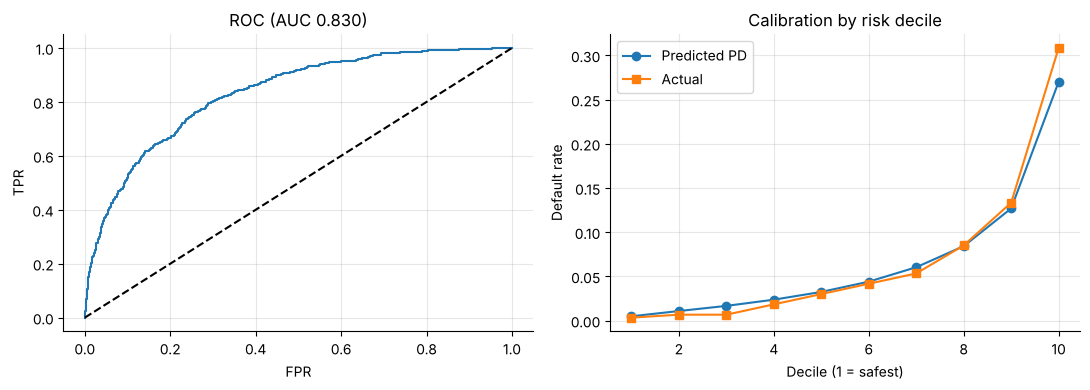

In [9]:
n = 20_000
loans = pd.DataFrame({
    'fico':        np.clip(np.random.normal(690, 70, n), 500, 850),
    'dti':         np.clip(np.random.normal(.33, .12, n), .05, .8),     # debt-to-income
    'ltv':         np.clip(np.random.normal(.75, .15, n), .2, 1.1),     # loan-to-value
    'income_k':    np.random.lognormal(4.3, .45, n),
    'delinq_2y':   np.random.poisson(.3, n),
})
# True (hidden) data-generating process
z = (-3.4 - .018 * (loans.fico - 690) + 3.0 * (loans.dti - .33) + 1.6 * (loans.ltv - .75)
     + .35 * loans.delinq_2y - .004 * (loans.income_k - 75))
loans['default'] = (np.random.rand(n) < 1 / (1 + np.exp(-z))).astype(int)
print(f"Loans: {n:,} | default rate {loans.default.mean():.2%}")

feats = ['fico', 'dti', 'ltv', 'income_k', 'delinq_2y']
X = (loans[feats] - loans[feats].mean()) / loans[feats].std()
Xtr, Xte, ytr, yte = train_test_split(X, loans.default, test_size=.3, random_state=1, stratify=loans.default)
model = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
pd_hat = model.predict_proba(Xte)[:, 1]

auc = roc_auc_score(yte, pd_hat)
fpr, tpr, _ = roc_curve(yte, pd_hat)
ks = (tpr - fpr).max()
print(f"Out-of-sample AUC {auc:.3f} | Gini {2*auc-1:.3f} | KS {ks:.3f}")
print(pd.Series(model.coef_[0], index=feats, name='std. coefficient (log-odds)').round(3))

# Calibration: predicted vs actual default by decile
cal = pd.DataFrame({'pred': pd_hat, 'actual': yte.values})
cal['decile'] = pd.qcut(cal.pred, 10, labels=False) + 1
cal_t = cal.groupby('decile').mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set(title=f'ROC (AUC {auc:.3f})', xlabel='FPR', ylabel='TPR')
ax[1].plot(cal_t.index, cal_t.pred, 'o-', label='Predicted PD'); ax[1].plot(cal_t.index, cal_t.actual, 's-', label='Actual')
ax[1].set(title='Calibration by risk decile', xlabel='Decile (1 = safest)', ylabel='Default rate'); ax[1].legend()
plt.tight_layout(); plt.show()

In [10]:
# --- Expected credit loss on the test portfolio ---
LGD = 0.40                                         # e.g. secured with collateral
bal = loans.loc[Xte.index, 'income_k'] * 3 * 1000 * loans.loc[Xte.index, 'ltv'].clip(upper=1)  # illustrative exposure ($)
book = pd.DataFrame({'PD': pd_hat, 'EAD': bal.values})
book['EL'] = book.PD * LGD * book.EAD
book['band'] = pd.qcut(book.PD, 5, labels=['A (best)', 'B', 'C', 'D', 'E (worst)'])
summary = book.groupby('band', observed=True).agg(loans=('PD', 'size'), avg_PD=('PD', 'mean'),
                                                   EAD=('EAD', 'sum'), ECL=('EL', 'sum'))
summary['coverage %'] = summary.ECL / summary.EAD * 100
print(summary.round(3))
print(f"\nTotal EAD ${book.EAD.sum():,.0f} | Total ECL ${book.EL.sum():,.0f} ({book.EL.sum()/book.EAD.sum():.2%} coverage)")

# --- Risk-based pricing: required rate so that risk-adjusted return meets target ---
def required_rate(pd_, lgd=LGD, funding=.035, opex=.010, target_roa=.010):
    # Expected annual loss rate is PD*LGD; add funding, operating cost, and desired profit
    return funding + opex + pd_ * lgd + target_roa

price = book.groupby('band', observed=True).PD.mean().apply(required_rate)
print("\nRisk-based loan pricing (min. rate):"); print(price.map('{:.2%}'.format))

           loans  avg_PD              EAD             ECL  coverage %
band                                                                 
A (best)    1200  0.0080 233,302,131.5470    728,166.3460      0.3120
B           1200  0.0200 222,352,904.3150  1,788,550.3250      0.8040
C           1200  0.0380 212,594,650.6500  3,247,796.2560      1.5280
D           1200  0.0720 216,302,317.3420  6,234,212.3190      2.8820
E (worst)   1200  0.1980 217,968,053.4030 17,300,430.0170      7.9370

Total EAD $1,102,520,057 | Total ECL $29,299,155 (2.66% coverage)

Risk-based loan pricing (min. rate):
band
A (best)      5.81%
B             6.31%
C             7.03%
D             8.39%
E (worst)    13.44%
Name: PD, dtype: str


**Takeaway.** The scorecard ranks risk well (AUC) and is calibrated (predicted ≈ actual by decile). Mapping PD to expected loss gives the provision a bank must hold, and mapping it to price shows why riskier borrowers pay more: the margin must cover expected loss before any profit.

## 9. WACC and Discounted Cash Flow (DCF) Valuation
**Concept.** A firm is worth the PV of its future free cash flows to all capital providers, discounted at the weighted average cost of capital.

$$FCFF = EBIT(1-t) + D\&A - CapEx - \Delta NWC$$
$$WACC = \frac{E}{V}r_e + \frac{D}{V}r_d(1-t), \qquad EV = \sum_{t=1}^{N}\frac{FCFF_t}{(1+WACC)^t} + \frac{TV}{(1+WACC)^N}$$
$$TV = \frac{FCFF_N(1+g)}{WACC-g}\quad(\text{Gordon growth})$$

Equity value = EV - net debt; divide by shares for value per share. The model below is for a **hypothetical** mid-size company, with revenue growth fading toward a long-term rate, and all assumptions in one dictionary so scenarios are easy.

In [11]:
assump = dict(
    rev0=2_000.0,                         # last-year revenue ($M)
    growth=[.12, .10, .08, .06, .05],     # 5-year revenue growth path
    ebit_margin=.18, tax=.25,
    da_pct=.04, capex_pct=.05, nwc_pct=.10,   # % of revenue; NWC as % of revenue
    rf=.04, beta=1.2, mrp=.055,           # CAPM inputs
    rd=.06, debt=600.0, cash=150.0,       # pre-tax cost of debt, debt, cash ($M)
    mkt_equity=3_600.0, shares=100.0,     # equity market value ($M), shares (M)
    g_terminal=.025)

def wacc_calc(a):
    re = a['rf'] + a['beta'] * a['mrp']
    E, D = a['mkt_equity'], a['debt']
    return E / (E + D) * re + D / (E + D) * a['rd'] * (1 - a['tax']), re

def dcf(a, wacc=None, g=None):
    w = wacc if wacc is not None else wacc_calc(a)[0]
    g = g if g is not None else a['g_terminal']
    rev = a['rev0'] * np.cumprod(1 + np.array(a['growth']))
    prev = np.concatenate([[a['rev0']], rev[:-1]])
    ebit = rev * a['ebit_margin']; nopat = ebit * (1 - a['tax'])
    fcff = nopat + rev * a['da_pct'] - rev * a['capex_pct'] - (rev - prev) * a['nwc_pct']
    t = np.arange(1, len(rev) + 1)
    pv_fcff = fcff / (1 + w) ** t
    tv = fcff[-1] * (1 + g) / (w - g)
    pv_tv = tv / (1 + w) ** t[-1]
    ev = pv_fcff.sum() + pv_tv
    eq = ev - a['debt'] + a['cash']
    proj = pd.DataFrame({'Revenue': rev, 'EBIT': ebit, 'NOPAT': nopat, 'FCFF': fcff, 'PV of FCFF': pv_fcff},
                        index=[f'Year {i}' for i in t])
    return dict(wacc=w, ev=ev, equity=eq, per_share=eq / a['shares'], tv_share=pv_tv / ev, proj=proj)

wacc_v, re_v = wacc_calc(assump)
res = dcf(assump)
print(f"Cost of equity {re_v:.2%} | WACC {wacc_v:.2%}")
print(res['proj'].round(1))
print(f"\nEnterprise value ${res['ev']:,.0f}M | Equity value ${res['equity']:,.0f}M | "
      f"Value/share ${res['per_share']:.2f} | Terminal value = {res['tv_share']:.0%} of EV")
print(f"Market price/share: ${assump['mkt_equity']/assump['shares']:.2f} -> "
      f"{'UNDER' if res['per_share'] > assump['mkt_equity']/assump['shares'] else 'OVER'}valued by "
      f"{abs(res['per_share']/(assump['mkt_equity']/assump['shares'])-1):.1%}")

Cost of equity 10.60% | WACC 9.73%
          Revenue     EBIT    NOPAT     FCFF  PV of FCFF
Year 1 2,240.0000 403.2000 302.4000 256.0000    233.3000
Year 2 2,464.0000 443.5000 332.6000 285.6000    237.2000
Year 3 2,661.1000 479.0000 359.3000 312.9000    236.9000
Year 4 2,820.8000 507.7000 380.8000 336.6000    232.2000
Year 5 2,961.8000 533.1000 399.8000 356.1000    223.9000

Enterprise value $4,338M | Equity value $3,888M | Value/share $38.88 | Terminal value = 73% of EV
Market price/share: $36.00 -> UNDERvalued by 8.0%


Terminal g    1.5%    2.0%    2.5%    3.0%    3.5%
WACC                                              
7.7%       47.7900 51.5000 55.9100 61.2600 67.8700
8.7%       40.3600 42.9800 46.0200 49.6000 53.8500
9.7%       34.7500 36.6800 38.8800 41.4000 44.3400
10.7%      30.3600 31.8300 33.4800 35.3400 37.4600
11.7%      26.8300 27.9700 29.2500 30.6600 32.2600


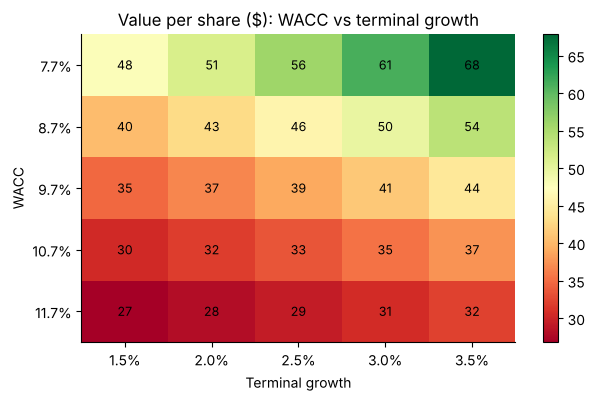

        EV ($M)  Value/share ($)
Bear 2,754.8000          23.0000
Base 4,337.9000          38.9000
Bull 5,932.4000          54.8000


In [12]:
# --- Sensitivity: value per share vs WACC and terminal growth ---
waccs = np.arange(wacc_v - .02, wacc_v + .0201, .01)
gs = np.arange(.015, .0351, .005)
grid = pd.DataFrame([[dcf(assump, w, g)['per_share'] for g in gs] for w in waccs],
                    index=[f'{w:.1%}' for w in waccs], columns=[f'{g:.1%}' for g in gs])
grid.index.name, grid.columns.name = 'WACC', 'Terminal g'
print(grid.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(grid.values, cmap='RdYlGn', aspect='auto')
ax.set_xticks(range(len(gs))); ax.set_xticklabels(grid.columns); ax.set_yticks(range(len(waccs))); ax.set_yticklabels(grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]): ax.text(j, i, f"{grid.values[i,j]:.0f}", ha='center', va='center', fontsize=9)
ax.set(title='Value per share ($): WACC vs terminal growth', xlabel='Terminal growth', ylabel='WACC'); ax.grid(False)
plt.colorbar(im); plt.show()

# --- Scenario analysis ---
def scen(**kw): a = {**assump, **kw}; return a
scenarios = {
  'Bear': scen(growth=[.06, .05, .04, .03, .03], ebit_margin=.15, g_terminal=.015),
  'Base': assump,
  'Bull': scen(growth=[.15, .13, .10, .08, .06], ebit_margin=.21, g_terminal=.03)}
print(pd.DataFrame({k: {'EV ($M)': dcf(v)['ev'], 'Value/share ($)': dcf(v)['per_share']} for k, v in scenarios.items()}).T.round(1))

**Takeaway.** Terminal value usually dominates DCF value (shown above), so the answer is highly sensitive to WACC and `g`. That is why analysts present a range (sensitivity grid + scenarios) rather than a single price. Also note the discipline check: `g` must stay below long-run nominal GDP growth, and WACC must exceed `g`.

## 10. Monte Carlo Valuation
**Concept.** Instead of three hand-picked scenarios, draw the uncertain inputs from distributions and run the DCF thousands of times. The output is a probability distribution of value: e.g. *"There is a 70% chance the stock is worth more than today's price."*

Mean $39.52 | Median $38.79 | 5th-95th pct $26.03 - $55.65
P(value > market price $36) = 62.9%


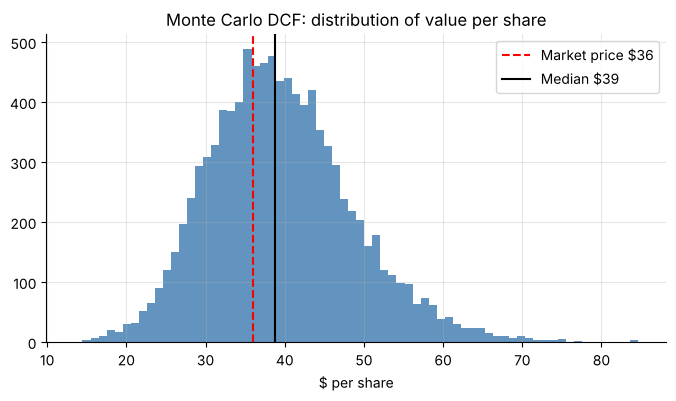

In [13]:
N = 10_000
rng = np.random.default_rng(7)
sims = []
for _ in range(N):
    a = {**assump,
         'growth': list(np.array(assump['growth']) + rng.normal(0, .02)),   # common growth shock
         'ebit_margin': float(np.clip(rng.normal(.18, .025), .08, .30)),
         'beta': float(np.clip(rng.normal(1.2, .15), .6, 2.0)),
         'g_terminal': float(np.clip(rng.normal(.025, .004), .01, .04))}
    sims.append(dcf(a)['per_share'])
sims = np.array(sims); mkt_px = assump['mkt_equity'] / assump['shares']

print(f"Mean ${sims.mean():.2f} | Median ${np.median(sims):.2f} | 5th-95th pct ${np.percentile(sims,5):.2f} - ${np.percentile(sims,95):.2f}")
print(f"P(value > market price ${mkt_px:.0f}) = {(sims > mkt_px).mean():.1%}")

fig, ax = plt.subplots()
ax.hist(sims, bins=70, color='steelblue', alpha=.85)
ax.axvline(mkt_px, c='r', ls='--', label=f'Market price ${mkt_px:.0f}')
ax.axvline(np.median(sims), c='k', label=f'Median ${np.median(sims):.0f}')
ax.set(title='Monte Carlo DCF: distribution of value per share', xlabel='$ per share'); ax.legend(); plt.show()

**Takeaway.** The distribution quantifies how much of the valuation answer is assumption risk, and gives a probability statement that is far more useful in an investment memo than a point estimate.

## 11. Extending with Real Data, and Resume Bullets

**Swap in real data (run locally with internet access):**
```python
import yfinance as yf
px = yf.download(['JPM', 'BAC', 'AAPL', 'XOM', 'SPY'], start='2019-01-01')['Close']
rets = px.pct_change().dropna()        # replaces the simulated `rets` in Sections 5-7
```
For Section 8 use the public **Lending Club** or **Freddie Mac loan-level** datasets; for Section 9 pull a real company's statements from its 10-K and replace the `assump` dictionary.

**Ideas to take it further (each is a strong interview talking point):** stress testing (CCAR-style rate and unemployment shocks on ECL), a transition-matrix / lifetime PD model for IFRS 9 Stage 2, Black-Litterman optimization, option pricing (Black-Scholes and binomial trees), and a Streamlit dashboard wrapping the DCF.

### Resume bullets (edit to match what you actually do and verify)
- *Built a Python financial-modeling toolkit covering TVM, amortization, NPV/IRR, bond duration & convexity, CAPM, Markowitz optimization, VaR/ES and DCF valuation; validated each model against closed-form results.*
- *Developed a logistic-regression PD scorecard (AUC ≈ 0.83 on out-of-sample data) and computed expected credit loss (PD x LGD x EAD) with risk-based loan pricing and decile calibration.*
- *Built a DCF with WACC build-up, terminal-value analysis, WACC/g sensitivity grid, bear/base/bull scenarios, and a 10,000-run Monte Carlo producing probability-weighted valuation ranges.*
- *Backtested 99% VaR across historical, parametric and Monte Carlo methods and showed ES captures tail risk that normal-based VaR understates on fat-tailed returns.*

> The AUC in the second bullet comes from simulated data. If you rerun with real loan data, replace it with the number printed in Section 8, and say on your resume which dataset you used.

### Key formulas cheat sheet
| Topic | Formula |
|---|---|
| PV / FV | $FV=PV(1+r)^n$ |
| Loan payment | $P=L\,r/(1-(1+r)^{-n})$ |
| NPV | $\sum CF_t/(1+r)^t$ |
| Bond duration | $D_{mod}=D_{mac}/(1+y/m)$ |
| CAPM | $r_f+\beta(E[R_m]-r_f)$ |
| Sharpe | $(R_p-r_f)/\sigma_p$ |
| Expected loss | $PD\times LGD\times EAD$ |
| WACC | $\frac{E}{V}r_e+\frac{D}{V}r_d(1-t)$ |
| Terminal value | $FCFF_N(1+g)/(WACC-g)$ |